<a href="https://colab.research.google.com/github/nsonyiwa-rose-nabakka/AI-STEM-shortcourse/blob/main/Week_7_Exploring_pretrained__models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Week 7: Exploring Pretrained Models**
This is a copy of my week 6 notebook. Part A is my week 6 work, unchanged. Part B is the week 7 work.

**Part A: **Week 6 Assignment: Discovering patterns in Data

**1. Select the dataset**
I am using the Oceanic Nino Index (919 overlapping 3-month seasons, 1950 to present). Each row has the sea surface temperature in the Nino 3.4 region (sst_c), the temperature anomaly (anom_c) and the official phase label (oni).

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

url = 'https://raw.githubusercontent.com/ahuang11/oni/master/oni.csv'
df = pd.read_csv(url)
print(df.shape)
df.head()

(919, 8)


,season,year,sst_c,anom_c,threshold,cumulative,ntotal,oni
0,DJF,1950,25.01,-1.32,below,1,13,la_nina
1,JFM,1950,25.36,-1.20,below,2,13,la_nina
2,FMA,1950,25.88,-1.12,below,3,13,la_nina
3,MAM,1950,26.24,-1.08,below,4,13,la_nina
4,AMJ,1950,26.35,-1.10,below,5,13,la_nina


2. **Prepare the features for clustering**

**Features chosen**
*   anom_c: how warm or cold the ocean is compared to normal (the state)
*   anom_change: which way the anomaly is moving (the direction)

**Features left out on purpose**
*   oni/threshold
*   sst_c
*   cumulative






In [ ]:
season_order = ['DJF', 'JFM', 'FMA', 'MAM', 'AMJ', 'MJJ', 'JJA', 'JAS', 'ASO', 'SON', 'OND', 'NDJ' ]
df['season_num'] = df['season'].map({s: i+1 for i, s in enumerate (season_order)})
df = df.sort_values (['year', 'season_num']).reset_index(drop=True)

df['anom_change'] = df['anom_c'] - df['anom_c'].shift(1)
data = df.dropna(subset=['anom_change']).copy()

features = ['anom_c', 'anom_change']
data[features].describe().round(2)

,anom_c,anom_change
count,918.00,918.00
mean,0.02,0.00
std,0.79,0.19
min,-2.04,-0.63
25%,-0.51,-0.11
50%,-0.04,0.01
75%,0.50,0.15
max,2.59,0.49


**Scaling.** K-Means groups points by distance, so a feature with a bigger spread would dominate. anom_c ranges from about -2 to +2.6C, while anom-change is mostly between -0.5 and +0.5C. I use standard scaler so both features have mean 0 and standard deviation 1 and count equally.

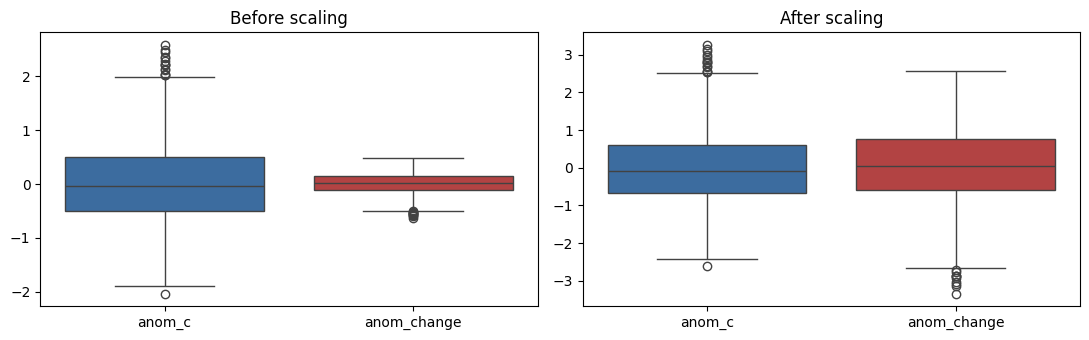

Means after scaling: [-0.  0.] | Std after scaling: [1. 1.]


In [ ]:
scaler = StandardScaler()
X = scaler.fit_transform(data[features])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (title, values) in zip(axes, [('Before scaling', data[features].values), ('After scaling', X)]):
    sns.boxplot(data=pd.DataFrame(values, columns=features), ax=ax, palette=['#2b6cb0', '#c53030'])
    ax.set_title(title)
plt.tight_layout(); plt.show()
print('Means after scaling:', X.mean(axis=0).round(2), '| Std after scaling:', X.std(axis=0).round(2))

3. **Apply K-Means and explore different numbers of clusters**
I fit K-means for k=2 to 10 and record three things:

*  **Inertia (elbow method):** total distance of points to their cluster centre. Lower is tighter, but it always falls as k grows, so i look for the 'elbow' where the gains slow down.
*  **Silhouette score:** how well each point fits its own cluster compared to the next one (-1 to 1, higher is better).
*  ** Davies-Bouldin index:** how similar each cluster is to its closest neighbour (lower is better).






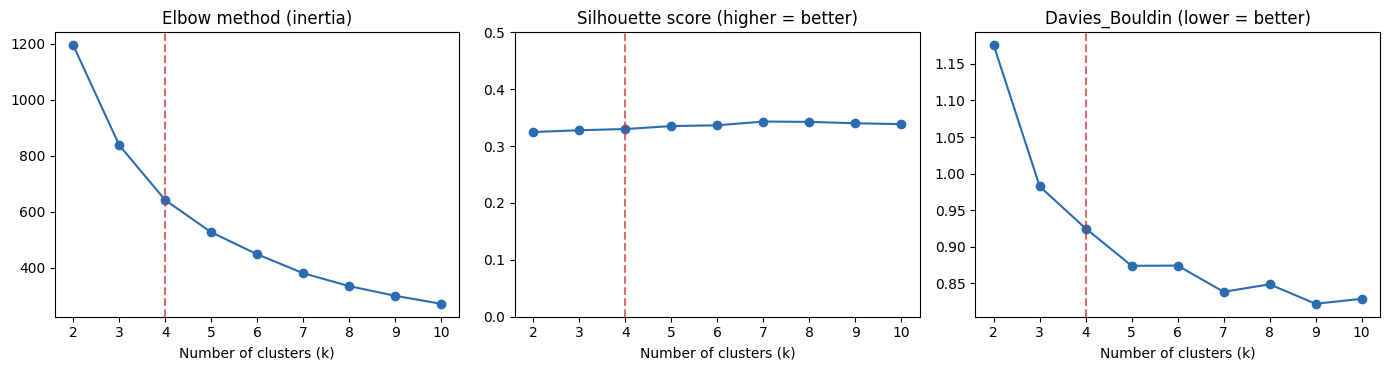

,inertia,silhouette,davies_bouldin
k,,,
2,1193.779,0.325,1.176
3,837.248,0.328,0.982
4,641.483,0.330,0.925
5,526.608,0.335,0.874
6,448.185,0.337,0.874
7,380.513,0.343,0.838
8,334.531,0.343,0.849
9,299.992,0.340,0.822
10,271.403,0.339,0.829


In [ ]:
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X)
    rows.append({'k': k,
                 'inertia': km.inertia_,
                 'silhouette': silhouette_score(X, km.labels_),
                 'davies_bouldin': davies_bouldin_score(X, km.labels_)})
scores = pd.DataFrame(rows).set_index('k')

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col, title in zip(axes, scores.columns,
                          ['Elbow method (inertia)', 'Silhouette score (higher = better)',
                           'Davies_Bouldin (lower = better)']):
    ax.plot(scores.index, scores[col], marker='o', color='#2b6cb0')
    ax.axvline(4, ls='--', color='#c53030', alpha=0.7)
    ax.set_title(title); ax.set_xlabel('Number of clusters (k)')
axes[1].set_ylim(0, 0.5) #full scale, so the small differences are not exaggerated
plt.tight_layout(); plt.show()
scores.round(3)


**Choosing k=4**


*  ** Elbow:** Inertia drops steeply from k=2 to 4 and then flattens out: each cluster after 4 removes much less.
*   **Davies-Bouldin:** Improves clearly up to k=4 and only slowly after that.
*   **Silhouette:** is quite flat (about 0.33 for every k).

With 4 clusters each group has a clear physical meaning; with 5 or more, groups start splitting the same behaviour into abit more or less.





In [ ]:
kmeans = KMeans(n_clusters=4, n_init=20, random_state=42)
data['cluster'] = kmeans.fit_predict(X)

#Cluster centres back in real units (degrees C) so they are easy to read
centres = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=features)

#Give each cluster a name from its centre: warm/cool state + warming/cooling direction
def name_cluster(row):
    state = 'Warm' if row['anom_c'] > 0 else 'Cool'
    trend = 'warming' if row['anom_change'] > 0 else 'cooling'
    return f'{state} & {trend}'
names = centres.apply(name_cluster, axis=1).to_dict()
data['group'] = data['cluster'].map(names)

group_order = ['Cool & cooling', 'Cool & warming', 'Warm & warming', 'Warm & cooling']
palette = {'Cool & cooling': '#1a365d', 'Cool & warming': '#63b3ed',
           'Warm & warming': '#c53030', 'Warm & cooling': '#ed8936'}
centres.index = centres.index.map(names)
centres.loc[group_order].round(2)

,anom_c,anom_change
Cool & cooling,-0.73,-0.15
Cool & warming,-0.31,0.11
Warm & warming,1.00,0.17
Warm & cooling,0.53,-0.19


4. **Describe the groups**
**Plot 1: the clusters in feature space.** Because i only used two features, i can plot the clusters directly without reducing dimensions. Each dot is one season; the X marks are the cluster centres.

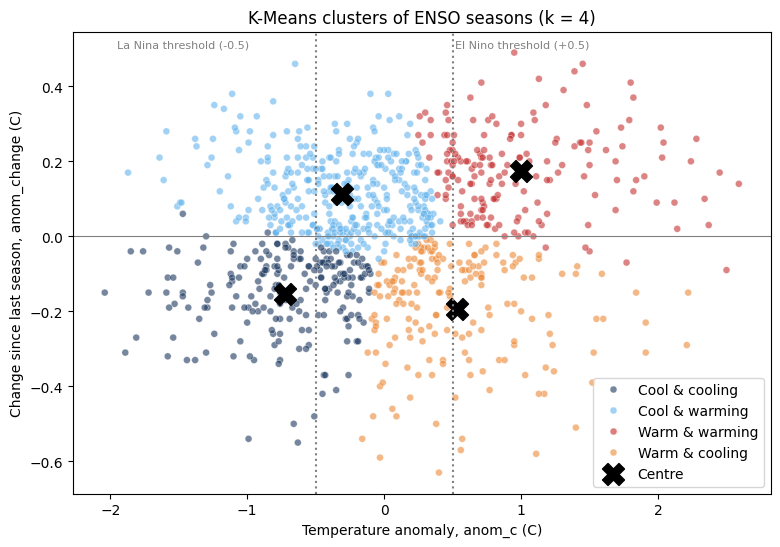

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=data, x='anom_c', y='anom_change', hue='group', hue_order=group_order,
                palette=palette, alpha=0.6, s=25, ax=ax)
ax.scatter(centres['anom_c'], centres['anom_change'], marker='X', s=250, c='black', label='Centre')
ax.axvline(0.5, ls=':', color='grey'); ax.axvline(-0.5, ls=':', color='grey')
ax.axhline(0, color='grey', lw=0.8)
ax.text(0.52, ax.get_ylim()[1]*0.92, 'El Nino threshold (+0.5)', color='grey', fontsize=8)
ax.text(-1.95, ax.get_ylim()[1]*0.92, 'La Nina threshold (-0.5)', color='grey', fontsize=8)
ax.set_xlabel('Temperature anomaly, anom_c (C)')
ax.set_ylabel('Change since last season, anom_change (C)')
ax.set_title('K-Means clusters of ENSO seasons (k = 4)')
ax.legend(loc='lower right'); plt.show()

**Plot 2: cluster profiles.** Box plots of each feature by group, plus the size of each group.

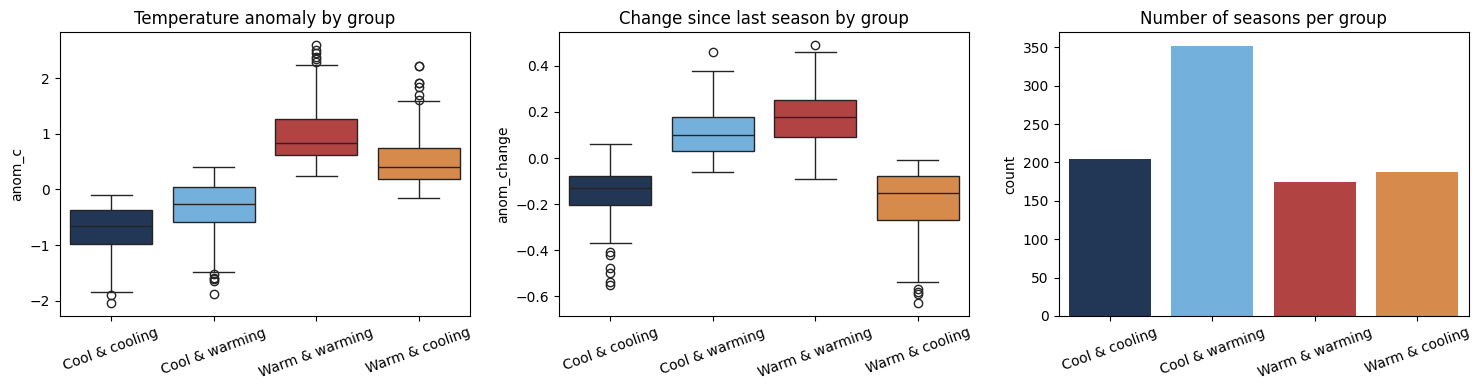

,seasons,mean_anom,mean_change,mean_sst
group,,,,
Cool & cooling,204,-0.73,-0.15,26.08
Cool & warming,352,-0.31,0.11,26.66
Warm & warming,175,1.00,0.17,27.84
Warm & cooling,187,0.53,-0.19,27.55


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=data, x='group', y='anom_c', order=group_order, hue='group', palette=palette, legend=False, ax=axes[0])
axes[0].set_title('Temperature anomaly by group')
sns.boxplot(data=data, x='group', y='anom_change', order=group_order, hue='group', palette=palette, legend=False, ax=axes[1])
axes[1].set_title('Change since last season by group')
sns.countplot(data=data, x='group', order=group_order, hue='group', palette=palette, legend=False, ax=axes[2])
axes[2].set_title('Number of seasons per group')
for ax in axes:
    ax.set_xlabel(''); ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

profile = data.groupby('group').agg(seasons=('anom_c', 'size'),
                                    mean_anom=('anom_c', 'mean'),
                                    mean_change=('anom_change', 'mean'),
                                    mean_sst=('sst_c', 'mean')).loc[group_order].round(2)
profile

**Plot 3: Checking the groups against the official labels.** The model never saw oni, so this is only used to interpret the clusters.

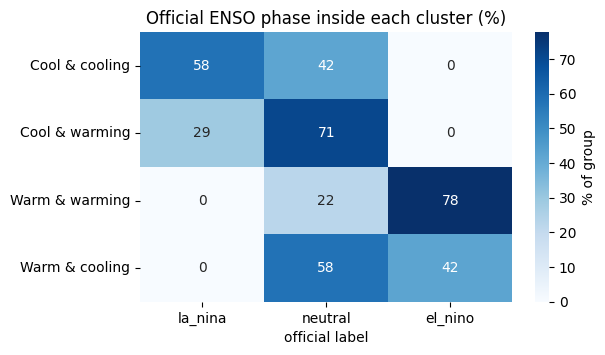

In [ ]:
ct = pd.crosstab(data['group'], data['oni'], normalize='index').loc[group_order, ['la_nina', 'neutral', 'el_nino']]
plt.figure(figsize=(6, 3.5))
sns.heatmap(ct * 100, annot=True, fmt='.0f', cmap='Blues', cbar_kws={'label': '% of group'})
plt.title('Official ENSO phase inside each cluster (%)'); plt.ylabel(''); plt.xlabel('official label')
plt.show()

**Plot 4: the clusters over time.** Colouring the anomaly line by cluster shows how real events move through the groups. Here i zoom in on 1995 to 2002, which includes the strong 1997/98 El nino and the long la nina after it.

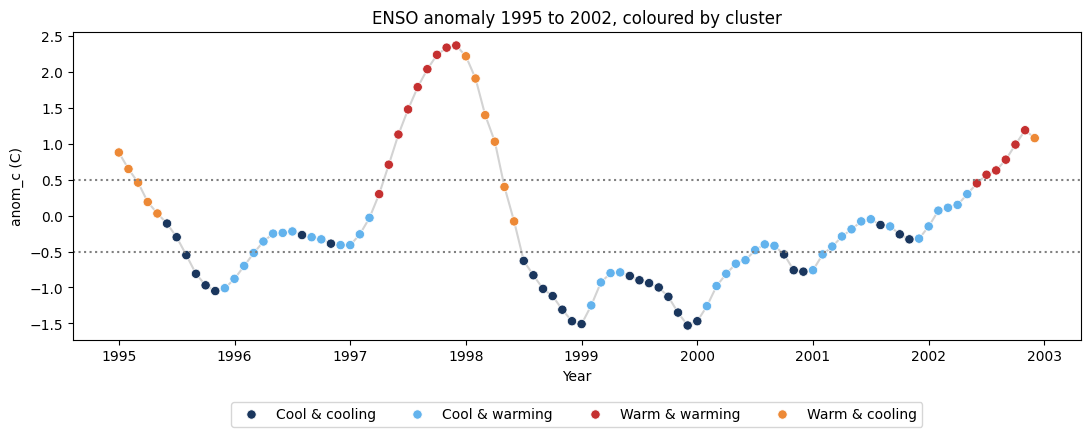

In [ ]:
data['t'] = data['year'] + (data['season_num'] - 1) / 12
window = data[(data['year'] >= 1995) & (data['year'] <=2002)]

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(window['t'], window['anom_c'], color='lightgrey', zorder=1)
sns.scatterplot(data=window, x='t', y='anom_c', hue='group', hue_order=group_order,
                palette=palette, s=45, ax=ax, zorder=2)
ax.axhline(0.5, ls=':', color='grey'); ax.axhline(-0.5, ls=':', color='grey')
ax.set_xlabel('Year'); ax.set_ylabel('anom_c (C)')
ax.set_title('ENSO anomaly 1995 to 2002, coloured by cluster')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=4); plt.show()

In [ ]:
# Which group usually comes next? (share of transitions from each group)
data['next_group'] = data['group'].shift(-1)
moves = pd.crosstab(data['group'], data['next_group'], normalize='index').loc[group_order, group_order]
(moves * 100).round(0)

next_group,Cool & cooling,Cool & warming,Warm & warming,Warm & cooling
group,,,,
Cool & cooling,67.0,33.0,0.0,0.0
Cool & warming,12.0,75.0,8.0,5.0
Warm & warming,0.0,1.0,78.0,21.0
Warm & cooling,13.0,10.0,5.0,71.0


5. **Discussion: what the clusters represent**
K-Means found four groups that match the stages of the ENSO Cycle which include;


*   **Warm & warming;** typical behaviour: anomaly about +1.0C and still rising, meaning el nino is building up or at its peak.  About 78% of these seasons are officially el nino.

*   **Warm & cooling;** anomaly about +0.5C but falling, meaning El Nino is fading, and neutral seasons because the ocean is on its way back to normal.

*   **Cool & warming;** anomaly about -0.3C and rising, meaning its mostly neutral with some late la nina seasons.

*   **Cool & cooling;** anomaly about -0.7C and falling; la nina is developing or deepening.





**Part B: Week 7, exploring pretrained models**

1. **Selected pretrained model**

**Name: **Chronos-Bolt (Small), amazon/chronos-bolt-small, 48million parameters, Apache-2.0 licence

**Link:** https://huggingface.co/amazon.chronos-bolt-small


2. **What the model is designed to do, its inputs and outputs**

Chronos-bolt is a foundation model for time-series forecasting. It was pretrained on almost 100 billion observations from many kinds of real and synthethic time series. Because of this it can forecast a new series it has never seen without any training. It is built on the T5 encoder-decoder transformer. The past values are split into patches of 16 time steps and passed through the encoder. The decoder then predicts several future steps at once.

**Input:** a single numeric time series. It is a 1D list of past values at regular time steps, up to 2048 values long. For my data this is the anom_c series in time order.

**Output**: a probabilistic forecast for the next h steps (up to 64 steps per pass). Instead of one number per step, it gives quantiles which means you get a central forecast plus an uncertainty range.


3. **How the model could be useful in my discipline**

My project is in climate and ocean science specifically the El Nino Southern Oscillation.

Chronos bolt could help in the following ways;
- **Quick baseline forecasts** of the ONI anomaly a few seasons ahead which can be compared with the official dynamical and statistical forecasts.

- **Forecasting other climatic series** with no training effort like station rainfall, river levels, lake levels, etc. Many of these records are short, which makes training a model from scratch hard.

- **Uncertainty ranges come built in**. They are useful for risk communication.

- **Gap filling and anomaly checking;** if an observed value is far outside the model's predicted range, it may be worth checking the data.

4. **How the pretrained model differs from my K-means model**

- My K-means model groups seasons into 4 ENSO seasons while chronos bolt predicts future values of the series.

- My k-means model has a very high interpretability, every centre has a physical meaning while chronos bolt has a low interpretability.

- The output of my model is one cluster label per season while chronos bolt forecasts quantiles for future seasons.

- My k-means models requires training where i fit it myself while chronos-bolt does not need any training.

- My K-means model describes the past and is fully explained by its centres while choronos bolt predicts the future using patterns learned from other data and cannot explain why.

5. **Could pretrained models, generative AI or NLP complement my project?**

**Pretrained models:** Yes. K-means tells me which stage of the ENSO cycle a season is in. Chronos can forecast the next few anom_c values. From these forecasts i can compute anom_change and pass both through y fitted scaler and K-means model.

**Generative AI:** Partly. A generative time-series model like chronos is useful since it gives forecasts with uncertainty rather than invented observations.

**NLP: **Only a small role. My data is numeric, so NLP is not needed for the core analysis. One possible use is reading text sources.

6. **Limitations and precautions before using such a model in science or engineering**

- **Spring predictability barrier: ENSO forecasts made in boreal spring are known to be unreliable. A general purpose model will not overcome this.

- **Training data leakage;** the model was trained on public datasets that may include climate series up to its release date. Back tests on past events may therefore look better than real forecasts would.

- **Overlapping seasons;** ONI values are 3-month running means, so neighbouring values are not independent. This can make errors look smaller than they really are.

